# 3. Graphiques

Chaque graphique est produit par une fonction de `src/visualisation.py` et enregistré dans `figures/`.

In [1]:
import os
import sys

import geopandas as gpd
import pandas as pd
import yaml

# on se place à la racine du projet
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

# paramètres communs du projet
with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# nos fonctions : seulement après s'être placé à la racine du projet
from src.variables import build_parts_croissance
import src.visualisation as vis

communes = gpd.read_parquet("data/clean/base_finale/base_finale_communes_variables.parquet")
gares = gpd.read_parquet("data/clean/base_finale/base_finale_gares.parquet")
gares_annees = pd.read_parquet("data/clean/base_finale/base_finale_gares_annees.parquet")
os.makedirs("figures", exist_ok=True)

## Partie 1. Où va la population ?

### Graphique 1 : la croissance démographique par commune de 2017 à 2023

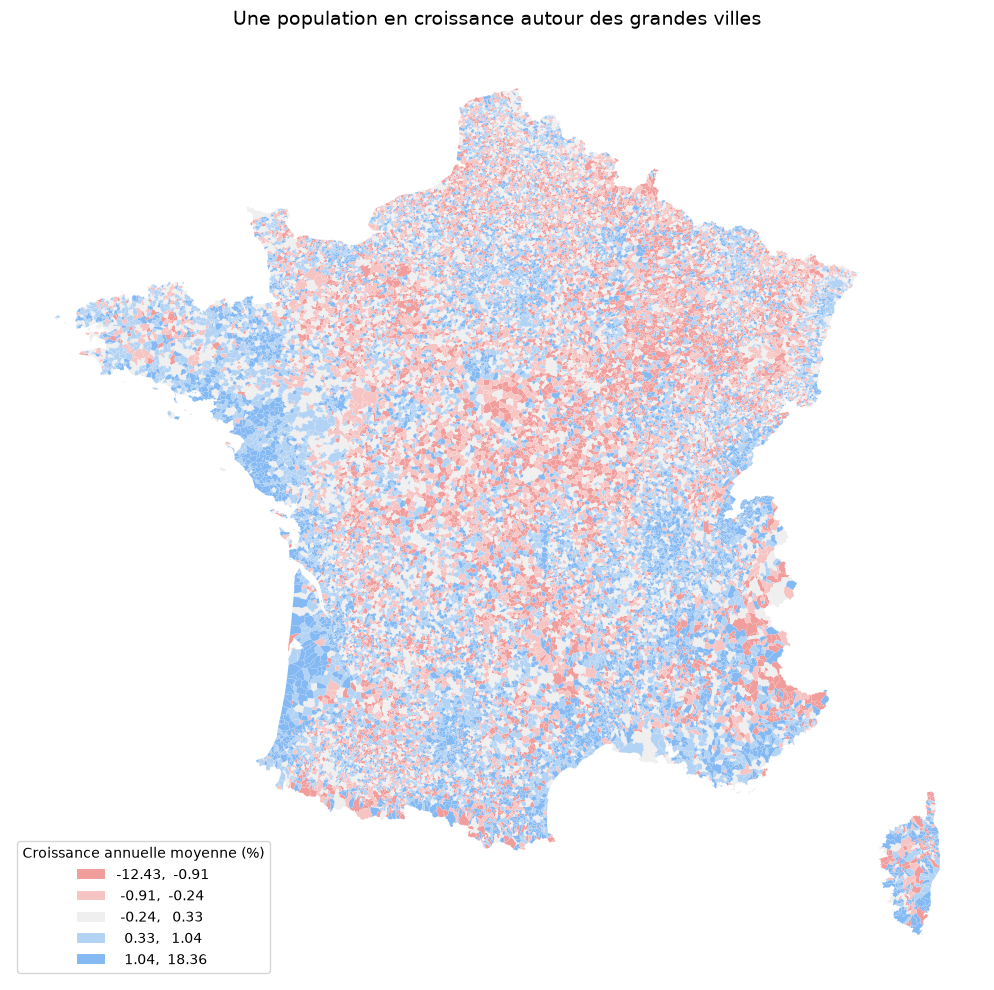

In [2]:
from src.visualisation import map_croissance_demographique

map = map_croissance_demographique()

On observe une croissance démographique concentrée autour des grandes villes (Nantes, Rennes, Bordeaux, Toulouse, Marseille, Lyon, Strasbourg, Paris)

### Graphique 2 : soldes naturels et migratoires par région

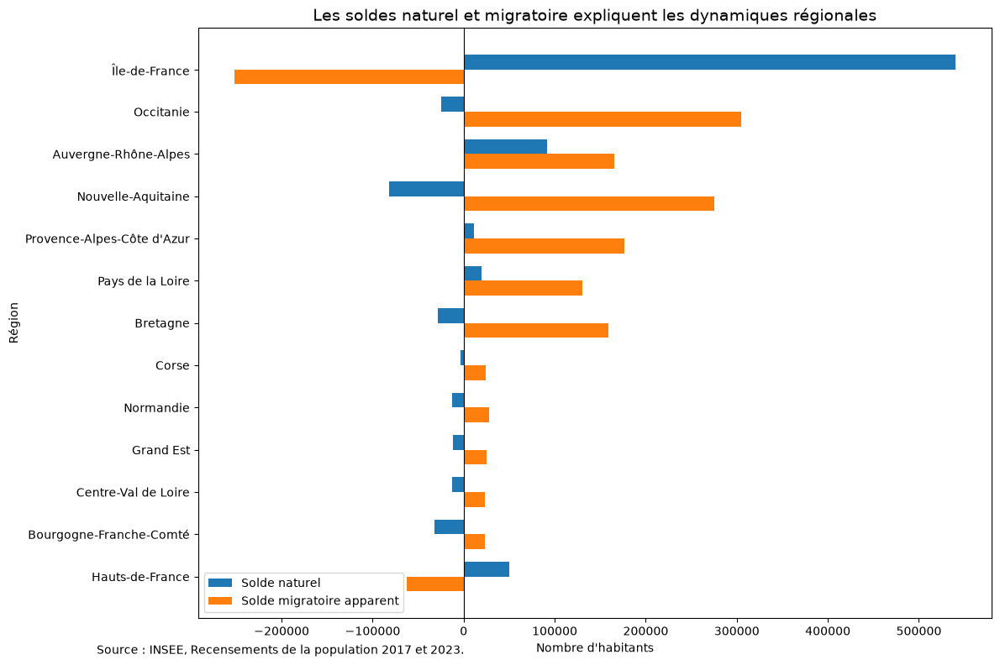

In [3]:
from src.visualisation import plot_soldes_regionaux

plot = plot_soldes_regionaux()

### Graphique 3 : histogramme des taux de croissance communaux

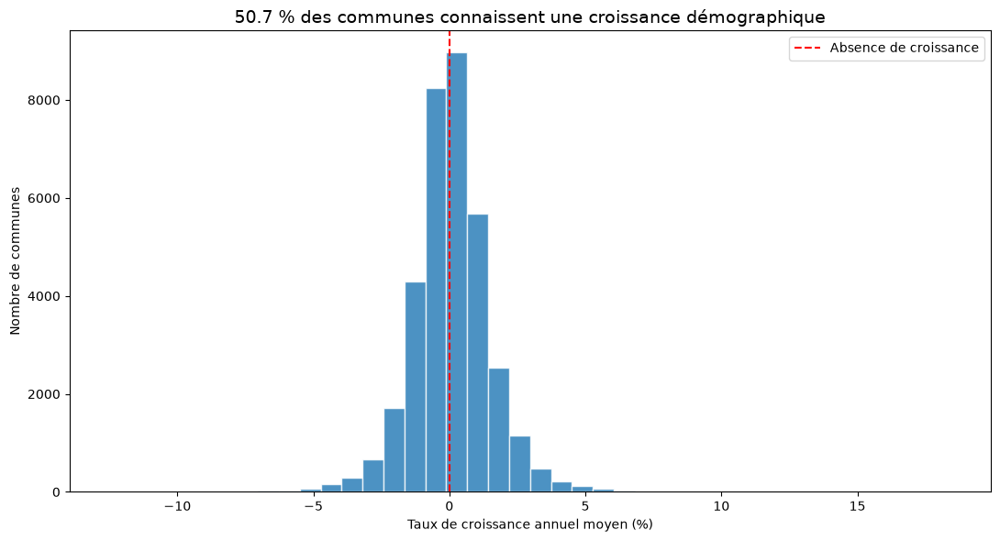

In [4]:
from src.visualisation import plot_hist_croissance

histogramme = plot_hist_croissance()

## Partie 2. Comment évolue la fréquentation des gares ?

### Graphique 4 : Evolution de la fréquentation des gares par catégorie (année de référence : 2019)

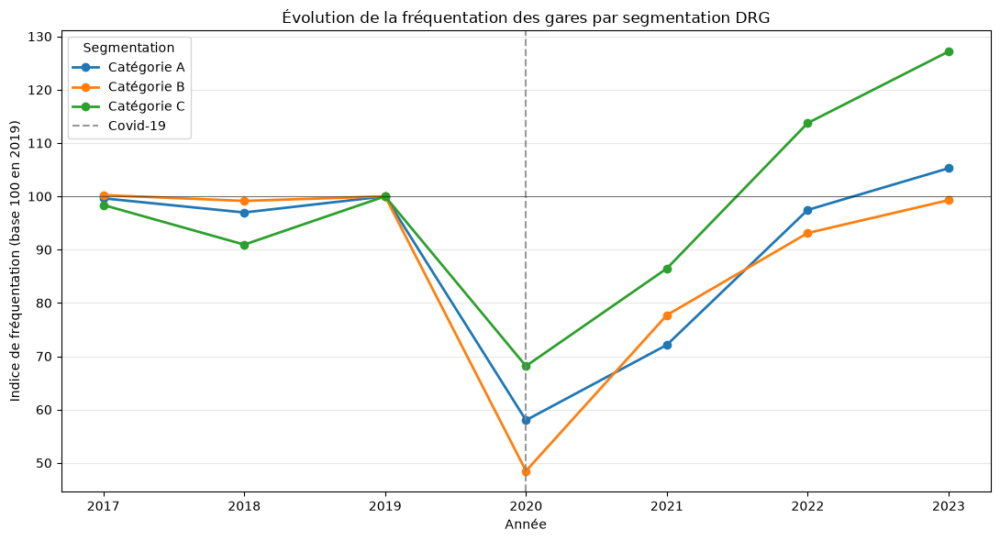

In [5]:
from src.visualisation import plot_evolution_frequentation

plot = plot_evolution_frequentation()

Les segment A, B et C sont défini par la SNCF en fonction de la fréquentation des gares (les gares A étan les plus fréquentées).

On remarque que les 3 segments connaissent des trajectoires similaires et ont tous été touchés par la crise sanitaire. 
Cependant; les moins touchées sont celle de catégorie C (baisse de 30% en 2020) qui ont rapidement récupéré puis dépassé leur fréquentation d'avant crise. Elles connaissaient en 2023 une fréquentation supérieure de presque 30% à leur niveau d'avant crise.

Les gares de catégorie B ont été les plus touchées enregistrant une baisse de 50%. Elles avaient à peine retrouvé leur niveau d'avant crise en 2023.

### Graphique 5 : Courbe de Lorenz des voyageurs en 2023

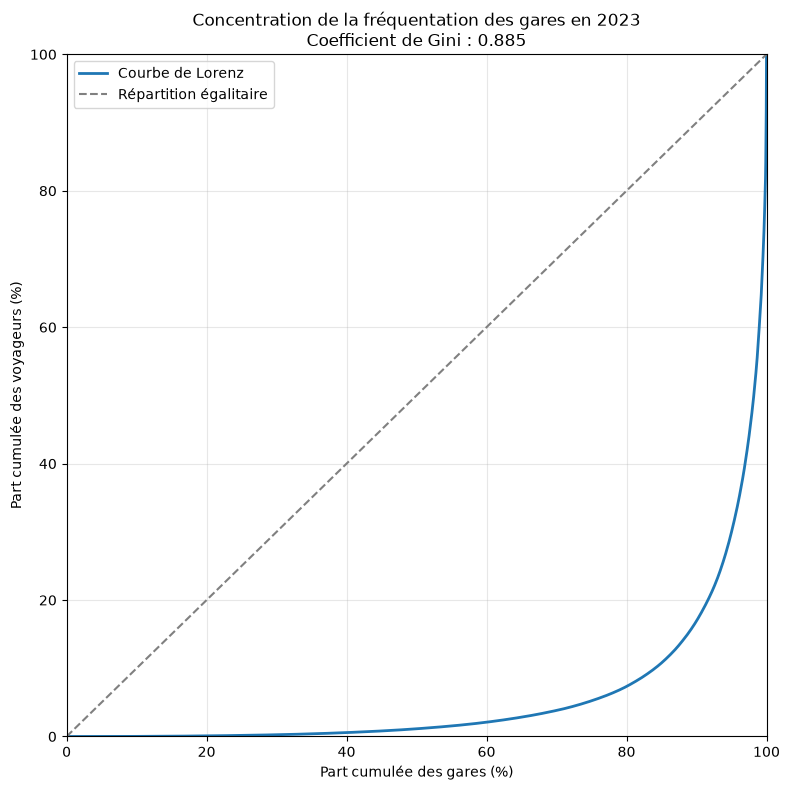

In [6]:
from src.visualisation import plot_lorenz_frequentation

plot = plot_lorenz_frequentation()

La distance de la courbe à la diagonale et le coefficient de Gini (arrondi à 0.9) montrent une forte concentration des voyageurs dans un petit nombre de gares.

L'analyse des valeurs nulles dans la partie jonction des bases nous permet de penser qu'ils n'ont pas d'influence sur le coefficient obtenu.

### Graphique 6 : Evolution des 15 gares les plus fréquentées

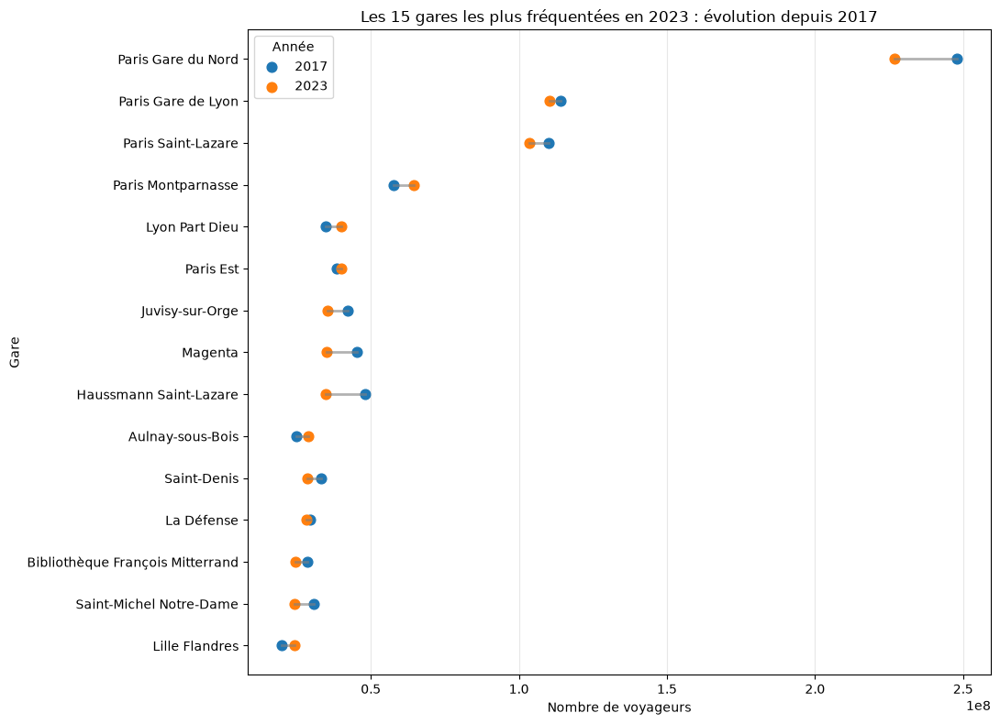

In [7]:
from src.visualisation import plot_evolution_top15_gares

plot = plot_evolution_top15_gares()

Remarque : les gares sont classées en fonction de leur fréquentation en 2023 et non de leur évolution.

Fréquentation en baisse : Paris Gare du Nord, Paris Gare de Lyon, Paris Saint-Lazare, Juvisy-sur-Orge, Magenta, Haussman Saint-Lazare, Saint-Denis, La Défense, Bibliothèque François Mitterand et Saint-Michel Notre-Dame

Fréquentation en hausse : Paris Montparnasse, Lyon Part-DIeu, Paris Est, Aulnay-sous-Bois et Lille Flandres

De manière générale, sur cet échantillon, l'ampleur de baisse de la fréquentation sur la période 2017-2023 est plus importante que celle de la hausse.

## Partie 3. Le rail suit-il la population ?

### Carte 7 : les gares et la croissance de la population

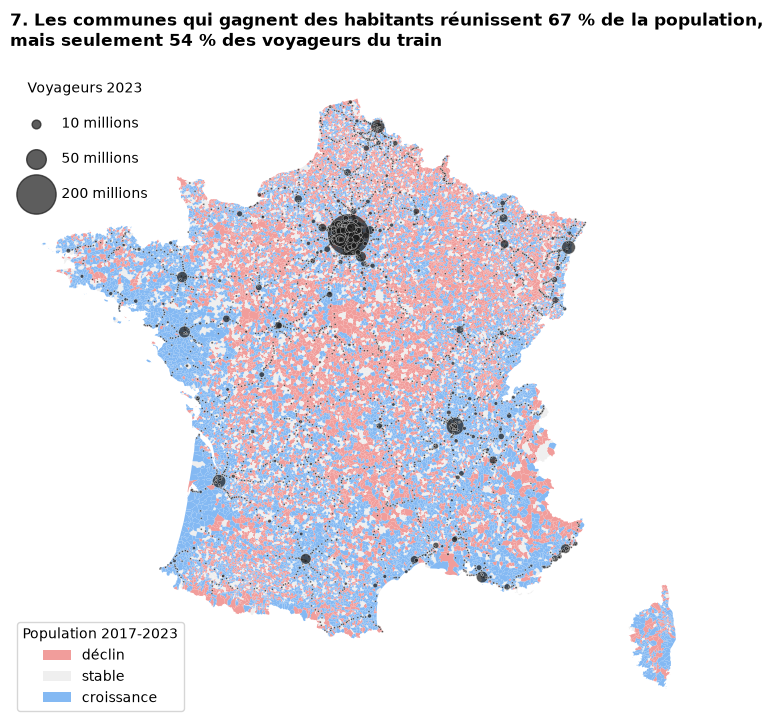

In [8]:
part_pop, part_voy = build_parts_croissance(communes, gares_annees, config["annee_fin"])
titre = (f"7. Les communes qui gagnent des habitants réunissent {part_pop:.0f} % de la population,\n"
         f"mais seulement {part_voy:.0f} % des voyageurs du train")
vis.map_gares(communes, gares, gares_annees, config["annee_fin"], titre, "figures/07_carte_gares.png");

La taille des bulles est proportionnelle au nombre de voyageurs de la gare en 2023. On observe que les grandes gares se concentrent dans les métropoles, dont Paris, qui perd des habitants. La croissance démographique se fait surtout sur la façade atlantique, autour de Toulouse, de Lyon et dans les Alpes. 

### Graphique 8 : croissance de la population et des voyageurs, en 4 quadrants

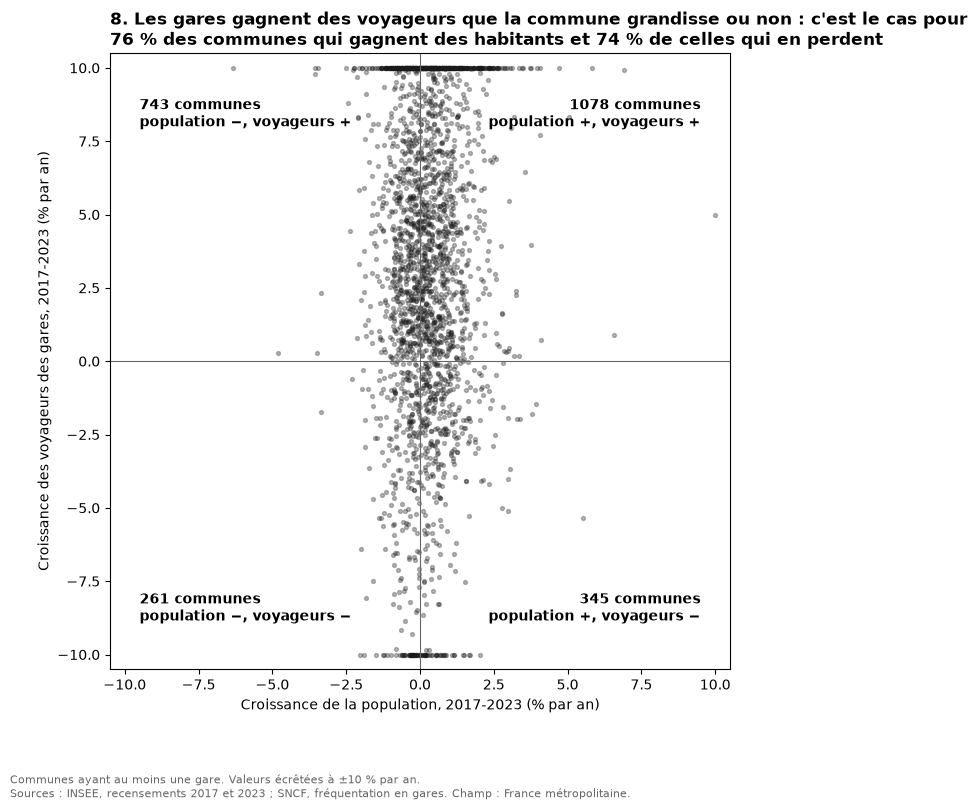

In [9]:
avec_gare = communes.dropna(subset=["tcam_pop_2017_2023", "tcam_voyageurs_2017_2023"])
hausse_voy = avec_gare["tcam_voyageurs_2017_2023"] > 0
part_croissance = hausse_voy[avec_gare["tcam_pop_2017_2023"] > 0].mean() * 100
part_declin = hausse_voy[avec_gare["tcam_pop_2017_2023"] < 0].mean() * 100
titre = (f"8. Les gares gagnent des voyageurs que la commune grandisse ou non : c'est le cas pour\n"
         f"{part_croissance:.0f} % des communes qui gagnent des habitants et {part_declin:.0f} % de celles qui en perdent")
vis.plot_quadrants(communes, titre, "figures/08_quadrants.png");

Les voyageurs augmentent dans trois communes sur quatre, que la population y progresse ou non : la hausse
de la fréquentation ne suit pas la démographie. 22 % des communes sont écrêtées, surtout des gares dont la
fréquentation a beaucoup varié.

### Carte 9 : les 4 profils de communes

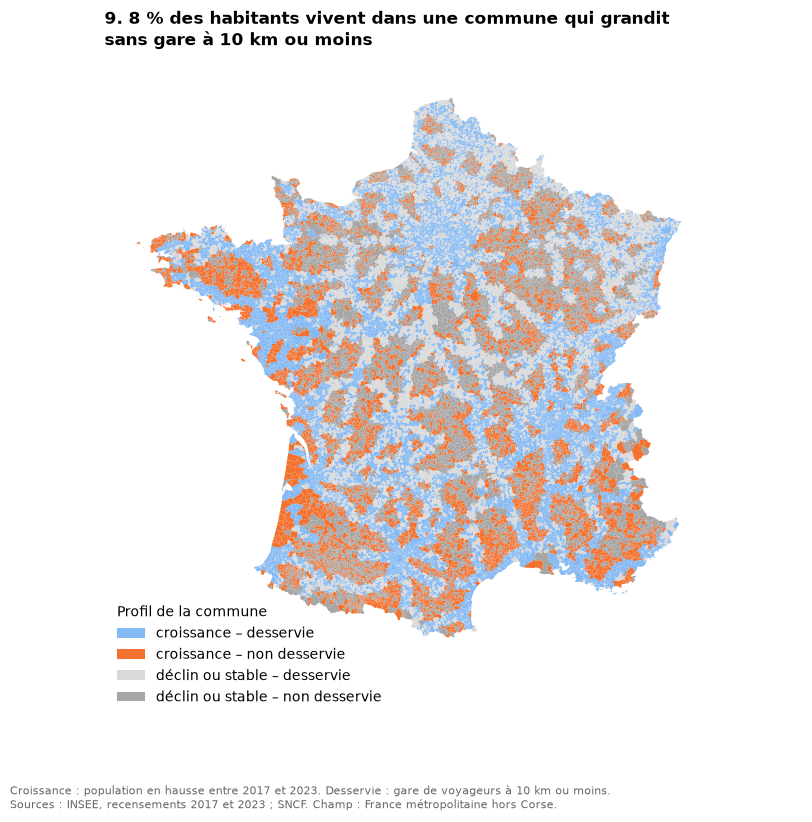

In [10]:
habitants = communes.groupby("profil")["pop_2023"].sum()
part = habitants["croissance – non desservie"] / habitants.sum() * 100
titre = f"9. {part:.0f} % des habitants vivent dans une commune qui grandit\nsans gare à 10 km ou moins"
vis.map_profils(communes, titre, "figures/09_carte_profils.png");

La croissance démographique se fait surtout près du rail (59 % des habitants), mais 6 611 communes grandissent
sans gare proche, en larges taches rurales : Landes, Gers, Bretagne intérieure, Midi et piémont alpin.

### Graphique 10 : croissance des voyageurs selon la trajectoire de la population

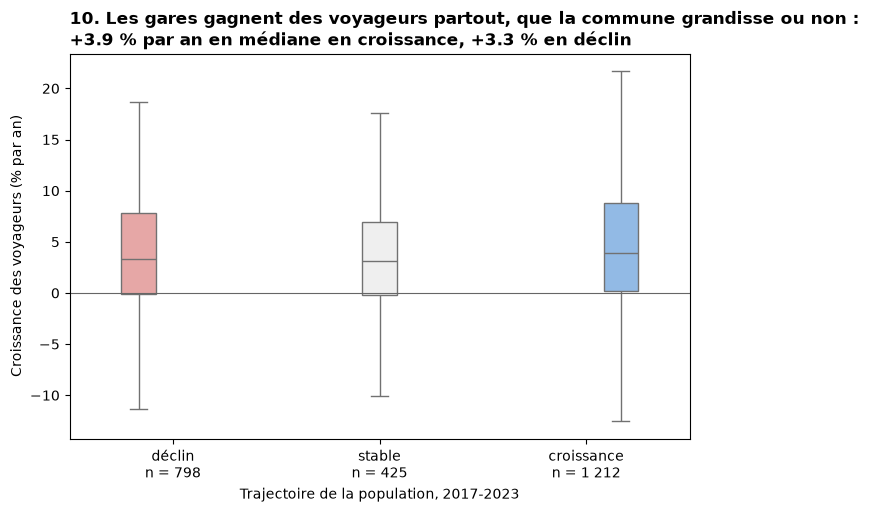

In [11]:
medianes = communes.groupby("trajectoire", observed=True)["tcam_voyageurs_2017_2023"].median()
titre = (f"10. Les gares gagnent des voyageurs partout, que la commune grandisse ou non :\n"
         f"{medianes['croissance']:+.1f} % par an en médiane en croissance, {medianes['déclin']:+.1f} % en déclin")
vis.plot_voyageurs_trajectoire(communes, titre, "figures/10_voyageurs_trajectoire.png");

Les communes qui gagnent des habitants voient leurs gares progresser à peine plus vite que celles qui
en perdent (+3,9 % contre +3,3 % par an en médiane) : la fréquentation des gares augmente partout et ne
suivent la démographie. La hausse vient donc d'autres facteurs (offre de trains, prix de l'essence,
télétravail…) que l'arrivée de nouveaux habitants. Les boîtes très larges montrent aussi de forts écarts
entre gares d'une même catégorie.

## Partie 4. Qui dépend de la voiture, et qui vit loin d'une gare ?

### Graphique 11 : part de la voiture selon la taille de la commune

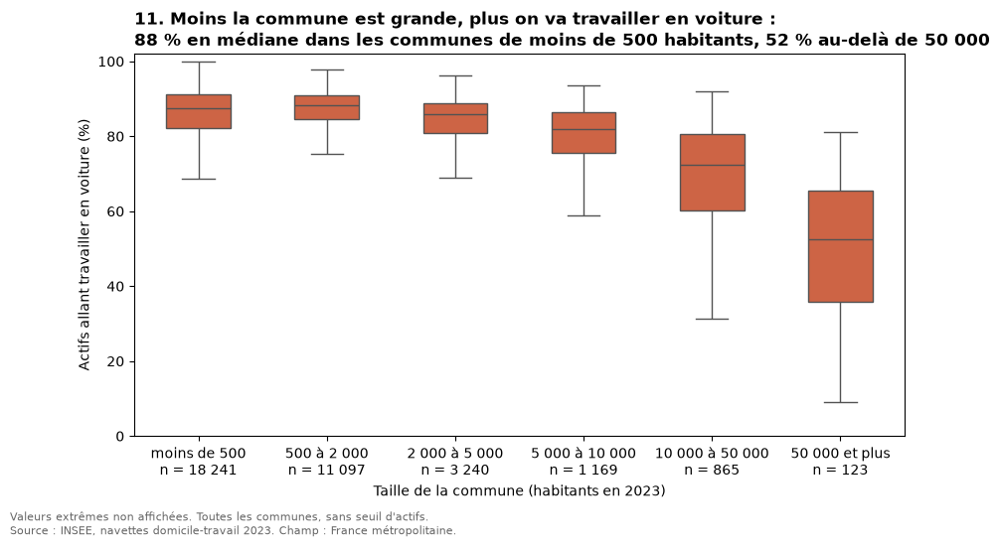

In [12]:
medianes = communes.groupby("classe_taille", observed=True)["part_voiture_toutes_2023"].median()
titre = (f"11. Moins la commune est grande, plus on va travailler en voiture :\n"
         f"{medianes.iloc[0]:.0f} % en médiane dans les communes de moins de 500 habitants, {medianes.iloc[-1]:.0f} % au-delà de 50 000")
vis.plot_voiture_taille(communes, titre, "figures/11_voiture_taille.png");

La voiture domine dans les petites communes, qui se ressemblent toutes (près de 90 %), puis recule au-delà
de 10 000 habitants ; les grandes villes restent très inégales entre elles (de moins de 10 % à plus de 80 %).

### Graphique 12 : part de la voiture selon la distance à la gare

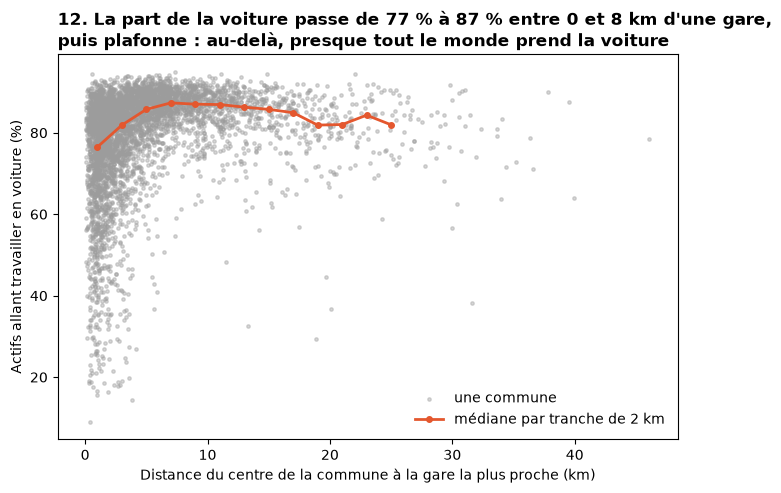

In [13]:
titre = ("12. La part de la voiture passe de 77 % à 87 % entre 0 et 8 km d'une gare,\n"
         "puis plafonne : au-delà, presque tout le monde prend la voiture")
vis.plot_voiture_distance(communes, titre, "figures/12_voiture_distance.png");

### Carte 13 : distance à la gare la plus proche

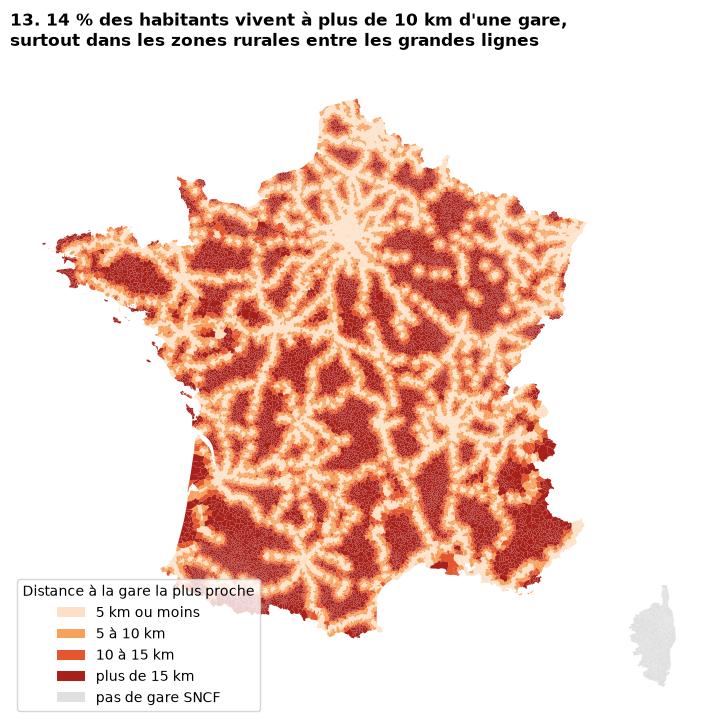

In [14]:
loin = communes["dist_gare_km"] > config["seuil_desservie_km"]
part_loin = communes.loc[loin, "pop_2023"].sum() / communes.loc[communes["dist_gare_km"].notna(), "pop_2023"].sum() * 100
titre = f"13. {part_loin:.0f} % des habitants vivent à plus de 10 km d'une gare,\nsurtout dans les zones rurales entre les grandes lignes"
vis.map_distance_gare(communes, titre, "figures/13_carte_distance_gare.png");

Le réseau dessine une étoile autour de Paris et des métropoles. L'éloignement touche surtout le rural peu dense (Gerse, Ardèche, Creuse, Landes). C'est là que la voiture s'impose: 84,5% des actifs vont travailler en voiture, contre 66,3% près d'une gare. 

### Graphique 14 : corrélations entre les variables communales

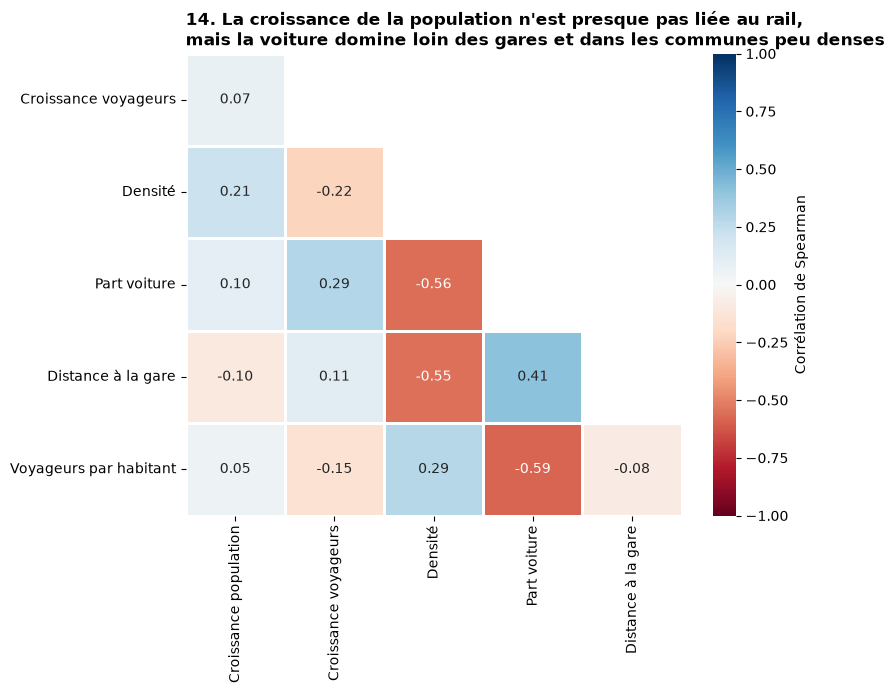

In [15]:
titre = "14. La croissance de la population n'est presque pas liée au rail,\nmais la voiture domine loin des gares et dans les communes peu denses"
vis.plot_correlations(communes, titre, "figures/14_correlations.png");

La croissance de la population n'est corrélée ni à la croissance des voyageurs (0,07) ni à la
distance à la gare (−0,10). La part de la voiture monte avec la distance à la gare (+0,41) et baisse
avec la densité (−0,56).

On peut remarquer que la croissance de la population ne semble pascorrélée ni à la croissance des voyageurs (0,07) ni à la distance à la gare (-0,10). Alors que pour la part de la voiture, on voit qu'elle monte avec la distance à la gare (+0,41) et baisse avec la densité (-0,56). 

## Pour la démo

### Carte 15 : carte interactive des gares

In [16]:
vis.map_gares_curseur(communes, gares, gares_annees, "figures/15_carte_gares_curseur.html")